# 07 — Deep Q-Network: one network for all the letters

The tabular methods have two limits that we measured: **one table per letter** (the agent that knows E knows
nothing about F, and cannot draw a letter it has never seen), and a table that **doubles in size with every
segment**. A **Deep Q-Network** (Mnih et al., 2015) replaces the table by a neural network that *computes*
$Q(o, a; \theta)$ from a description $o$ of the state. We train **a single network on the 10 letters at
once**, and give it the target letter as part of its input (like the destination in Taxi-v3, or the goal in
"universal value function approximators", Schaul et al., 2015).

This notebook (step 7a) checks whether the DQN learns the 10 training letters and compares it with
tabular Q-learning. Step 7b will test it on letters it has never seen.

## What the network sees: a 170-number observation

| part | size | content |
|---|---|---|
| target letter | 72 | one bit per possible unit segment of the 5×5 grid (horizontal, vertical, diagonal): 1 if it belongs to the letter |
| segments drawn | 72 | 1 if this segment of the letter has already been drawn |
| pen position | 25 | one-hot: 1 on the cell where the pen is |
| pen down | 1 | 1 if the previous move was drawn with the pen down |

This description does not depend on the letter: the same network can read any letter.

## The network and the update

A multilayer perceptron: 170 → 256 → 256 → 17 (ReLU), one output per action.
The target is the same as in Q-learning, but computed by a **target network** $\theta^-$:

$$y = R + \gamma \max_a Q(o', a; \theta^-) \qquad (y = R \text{ after STOP})$$

and the network is trained by gradient descent (Adam) to minimise the Huber loss between $Q(o, A; \theta)$ and $y$.

**The two ingredients of DQN** (Mnih et al., 2015):
- **experience replay**: every transition $(o, a, r, o', \text{terminated})$ is stored in a memory of 100,000
  transitions; the network learns on random mini-batches of 64 transitions drawn from it. Consecutive steps
  of an episode are strongly correlated; sampling at random breaks this correlation, and each transition is reused many times;
- **target network**: a copy of the network, updated every 1,000 steps, computes $y$. Without it the target
  would move at every update (the network would chase its own predictions) and learning could diverge.

```
Initialise Q(.; theta) at random, theta- <- theta, empty memory D
For step = 1 ... 300,000:
    with probability epsilon a random action, otherwise argmax_a Q(o, a; theta)
    play it, observe r, o'; store (o, a, r, o', terminated) in D
    (if the episode ends: new episode on a random letter, random natural start)
    every 4 steps: sample 64 transitions from D,
                   y = r + gamma max_a Q(o', a; theta-)   (y = r if terminated)
                   gradient step on Huber(Q(o, a; theta), y)
    every 1,000 steps: theta- <- theta
```

| Parameter | Value |
|---|---|
| training steps | 300,000 (all letters together) |
| ε | 1 → 0.05 over the first 60 % of the steps |
| γ | 0.99 |
| learning rate (Adam) | 0.0005 |
| mini-batch | 64, one gradient step every 4 environment steps (as in Mnih et al.) |
| memory | 100,000 transitions; learning starts after 5,000 steps |
| target network update | every 1,000 steps |
| runs | 3 seeds |

In [2]:
import sys
sys.path.insert(0, "..")

import csv
import os
import time
import numpy as np
import matplotlib.pyplot as plt
import torch
from IPython.display import Image

from src.letters import TRAINING_LETTERS
from src.environment import LetterWritingEnv, Rewards
from src.dqn import train_dqn, QNetwork, Observer, greedy_episode, evaluate, OBS_SIZE, N_SEGMENTS
from src.visualization import plot_episodes, animate_episodes, SURFACE, TEXT, MUTED

torch.set_num_threads(1)   # with such a small network, one CPU thread is faster than several
GAMMA = 0.99
SEEDS = [0, 1, 2]
RETRAIN = False            # True: train again even if saved models exist in results/

optimal = {}
with open("../results/02_optimal_returns.csv") as f:
    for row in csv.DictReader(f):
        optimal.setdefault(row["letter"], []).append(float(row["v_star"]))
v_star_mean = {name: np.mean(v) for name, v in optimal.items()}
with open("../results/03_q_learning_summary.csv") as f:
    q_summary = {r["letter"]: r for r in csv.DictReader(f)}


def style(ax, title=None, xlabel=None, ylabel=None):
    ax.set_facecolor(SURFACE)
    ax.grid(axis="y", color="#ecebe7", lw=0.8)
    ax.tick_params(colors=MUTED, labelsize=8)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color("#c3c2b7")
    if title:
        ax.set_title(title, color=TEXT, fontsize=10)
    if xlabel:
        ax.set_xlabel(xlabel, color=MUTED, fontsize=9)
    if ylabel:
        ax.set_ylabel(ylabel, color=MUTED, fontsize=9)

## 1. An example of observation

The observation of the starting state of E (pen at (0, 3), nothing drawn yet).

In [3]:
env = LetterWritingEnv("E")
obs = Observer(env)(env.start_states()[0])
print(f"observation size: {obs.size}")
print(f"target letter bits set to 1:  {int(obs[:N_SEGMENTS].sum())}  (E has {env.k} segments)")
print(f"segments drawn bits set to 1: {int(obs[N_SEGMENTS:2 * N_SEGMENTS].sum())}")
cell = int(np.argmax(obs[2 * N_SEGMENTS:2 * N_SEGMENTS + 25]))
print(f"pen position: cell {cell} = (row {cell // 5}, col {cell % 5})")
print(f"pen down: {int(obs[-1])}")

observation size: 170
target letter bits set to 1:  12  (E has 12 segments)
segments drawn bits set to 1: 0
pen position: cell 3 = (row 0, col 3)
pen down: 0


## 2. Training: 3 runs of 300,000 steps

Each run trains one network on the 10 letters (a random letter at each episode) and evaluates its greedy
policy on every letter every 10,000 steps. The trained networks are saved in `results/`, so that the next
notebooks (and a second execution of this one) can load them instead of training again.
**This cell takes about 15 minutes** (4 to 5.5 minutes per run) the first time, a few seconds afterwards.

In [4]:
runs = []
for seed in SEEDS:
    model_path = f"../results/07_dqn_seed{seed}.pt"
    curve_path = f"../results/07_dqn_seed{seed}_curves.npz"
    if os.path.exists(model_path) and os.path.exists(curve_path) and not RETRAIN:
        net = QNetwork()
        net.load_state_dict(torch.load(model_path))
        data = np.load(curve_path)
        run = {"net": net, "eval_steps": data["eval_steps"], "perfect": data["perfect"], "returns": data["returns"],
               "episode_end_steps": data["episode_end_steps"], "time": float(data["time"])}
        print(f"seed {seed}: loaded from results/")
    else:
        print(f"--- seed {seed} ---")
        res = train_dqn(TRAINING_LETTERS, total_steps=300_000, gamma=GAMMA, eval_every=10_000, seed=seed)
        perfect = np.array([[r[name][1] for name in TRAINING_LETTERS] for r in res["eval_results"]])
        returns = np.array([[r[name][0] for name in TRAINING_LETTERS] for r in res["eval_results"]])
        torch.save(res["net"].state_dict(), model_path)
        np.savez(curve_path, eval_steps=res["eval_steps"], perfect=perfect, returns=returns,
                 episode_end_steps=res["episode_end_steps"], time=res["time"])
        run = {"net": res["net"], "eval_steps": res["eval_steps"], "perfect": perfect, "returns": returns,
               "episode_end_steps": res["episode_end_steps"], "time": res["time"]}
        print(f"seed {seed}: {res['time'] / 60:.1f} min")
    run["net"].eval()
    runs.append(run)

--- seed 0 ---
step  10,000  epsilon 0.95  perfect drawings 0%  (8 s)
step  20,000  epsilon 0.89  perfect drawings 0%  (19 s)
step  30,000  epsilon 0.84  perfect drawings 0%  (31 s)
step  40,000  epsilon 0.79  perfect drawings 0%  (46 s)
step  50,000  epsilon 0.74  perfect drawings 0%  (62 s)
step  60,000  epsilon 0.68  perfect drawings 0%  (77 s)
step  70,000  epsilon 0.63  perfect drawings 0%  (91 s)
step  80,000  epsilon 0.58  perfect drawings 0%  (102 s)
step  90,000  epsilon 0.53  perfect drawings 5%  (118 s)
step 100,000  epsilon 0.47  perfect drawings 0%  (137 s)
step 110,000  epsilon 0.42  perfect drawings 8%  (156 s)
step 120,000  epsilon 0.37  perfect drawings 10%  (172 s)
step 130,000  epsilon 0.31  perfect drawings 10%  (185 s)
step 140,000  epsilon 0.26  perfect drawings 3%  (199 s)
step 150,000  epsilon 0.21  perfect drawings 0%  (213 s)
step 160,000  epsilon 0.16  perfect drawings 22%  (226 s)
step 170,000  epsilon 0.10  perfect drawings 18%  (240 s)
step 180,000  epsilo

## 3. Results on the 10 training letters

### Learning curves
Left: fraction of perfect drawings (all letters, all starting points) for each run. Right: mean greedy return
as a % of the optimum.

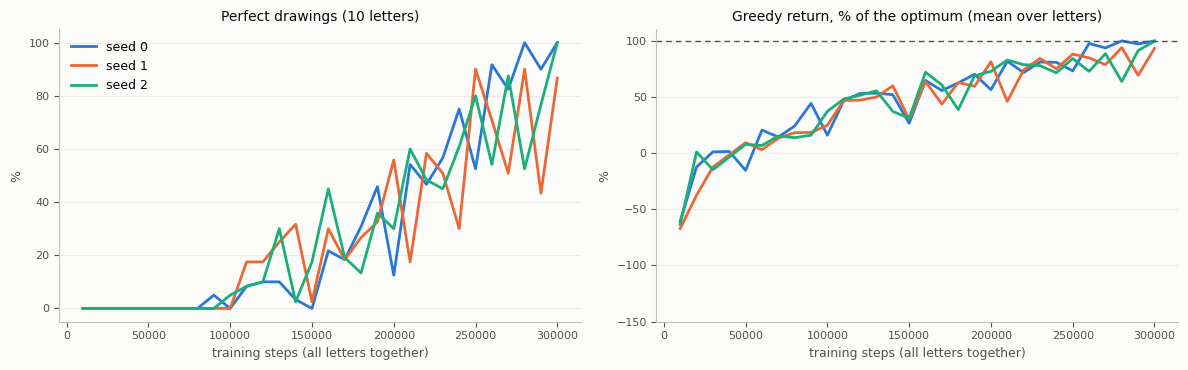

In [5]:
colors = ["#2a78d6", "#eb6834", "#1baf7a"]
v_vec = np.array([v_star_mean[n] for n in TRAINING_LETTERS])
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), facecolor=SURFACE)
for run, seed, c in zip(runs, SEEDS, colors):
    axes[0].plot(run["eval_steps"], 100 * run["perfect"].mean(1), color=c, lw=2, label=f"seed {seed}")
    axes[1].plot(run["eval_steps"], 100 * (run["returns"] / v_vec).mean(1), color=c, lw=2, label=f"seed {seed}")
axes[1].axhline(100, color=MUTED, lw=1, ls=(0, (4, 3)))
axes[1].set_ylim(-150, 110)
style(axes[0], "Perfect drawings (10 letters)", "training steps (all letters together)", "%")
style(axes[1], "Greedy return, % of the optimum (mean over letters)", "training steps (all letters together)", "%")
axes[0].legend(frameon=False, fontsize=9)
fig.tight_layout()
fig.savefig("../results/07_dqn_learning.png", dpi=150, facecolor=SURFACE)
plt.show()

### Final table, compared with tabular Q-learning (notebook 03)

In [6]:
print(f"{'letter':<7}{'DQN % of v* (3 runs)':>24}{'DQN perfect':>13}{'Q-learning % of v*':>20}")
for i, name in enumerate(TRAINING_LETTERS):
    pct = [100 * run["returns"][-1, i] / v_star_mean[name] for run in runs]
    perf = np.mean([run["perfect"][-1, i] for run in runs])
    print(f"{name:<7}{np.mean(pct):>16.0f} ± {np.std(pct):<5.1f}{perf:>12.0%}{float(q_summary[name]['pct_optimum_mean']):>19.0f}%")

print("\nHow much experience did each method need?")
for run, seed in zip(runs, SEEDS):
    hits = np.flatnonzero(run["perfect"].mean(1) == 1)
    if len(hits):
        step = run["eval_steps"][hits[0]]
        episodes = int((run["episode_end_steps"] <= step).sum())
        print(f"  DQN seed {seed}: every letter perfect after {step:,} steps = {episodes:,} episodes in total, "
              f"about {episodes // len(TRAINING_LETTERS):,} episodes per letter   (training time {run['time'] / 60:.1f} min)")
    else:
        print(f"  DQN seed {seed}: not every letter perfect at the end")
first = [float(q_summary[n]["episodes_to_first_perfect_median"]) for n in TRAINING_LETTERS]
print(f"  Q-learning: first perfect drawing after {min(first):,.0f} to {max(first):,.0f} episodes per letter, "
      f"one separate table per letter (30,000 episodes each)")

letter     DQN % of v* (3 runs)  DQN perfect  Q-learning % of v*
I                   100 ± 0.0          100%                 97%
L                   100 ± 0.6          100%                100%
T                   100 ± 0.2          100%                 97%
E                   100 ± 0.2          100%                 97%
F                    91 ± 12.9          89%                 98%
H                    99 ± 0.5          100%                 93%
N                   100 ± 0.3          100%                 98%
Z                    98 ± 1.1          100%                 99%
V                    87 ± 18.2          67%                 99%
X                    99 ± 0.7          100%                 97%

How much experience did each method need?
  DQN seed 0: every letter perfect after 280,000 steps = 11,491 episodes in total, about 1,149 episodes per letter   (training time 7.3 min)
  DQN seed 1: not every letter perfect at the end
  DQN seed 2: every letter perfect after 300,000 steps = 12,1

### The drawings of the DQN (run 0)

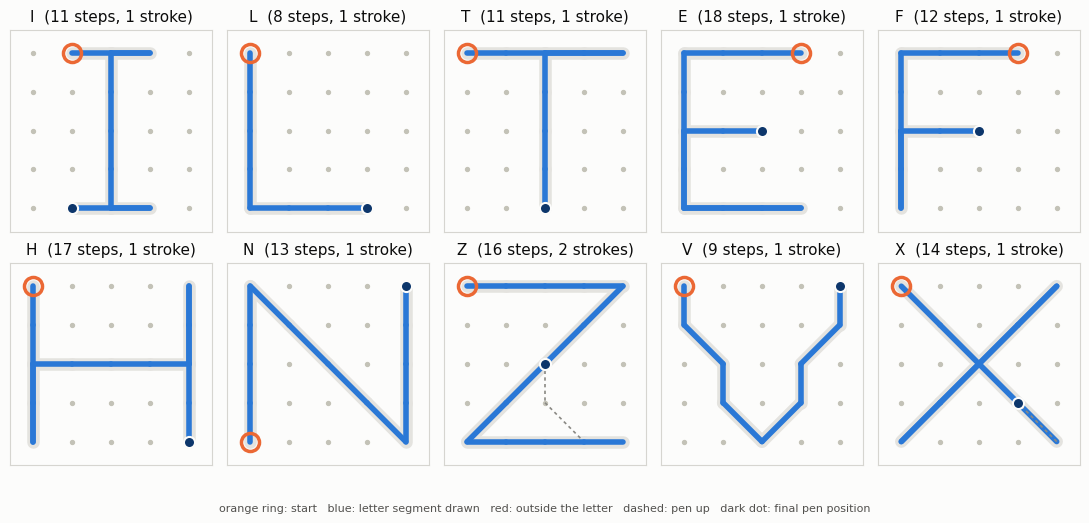

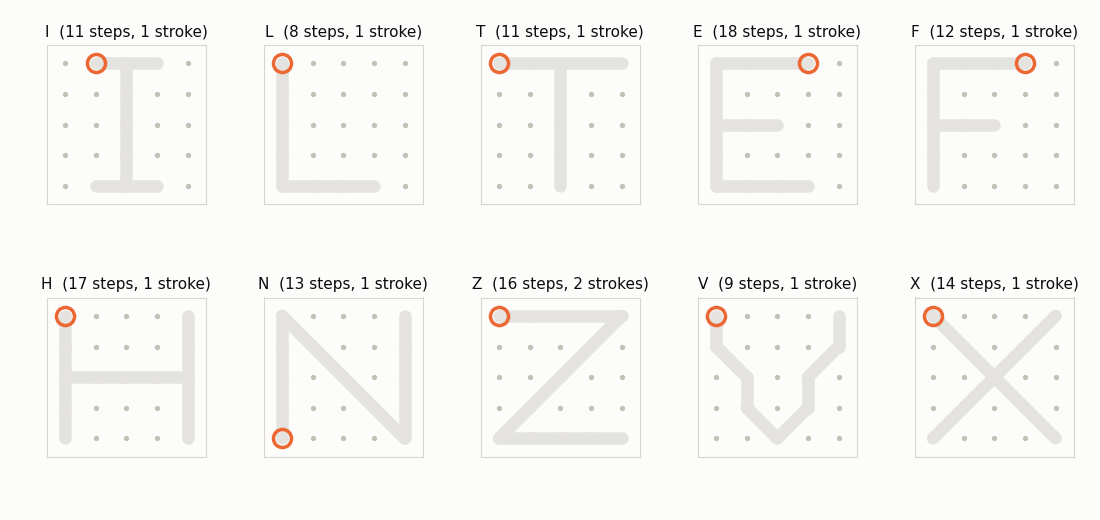

In [7]:
net = runs[0]["net"]
panels = []
for name in TRAINING_LETTERS:
    env = LetterWritingEnv(name)
    ep = greedy_episode(net, env, env.letter.start_points[0], GAMMA)
    panels.append((env.letter, ep["history"], f"{name}  ({ep['steps']} steps, {ep['strokes']} stroke{'s' * (ep['strokes'] > 1)})"))
plot_episodes(panels, path="../results/07_dqn_drawings.png")
plt.show()
animate_episodes(panels, "../results/07_dqn_drawings.gif")
Image(filename="../results/07_dqn_drawings.gif")

## What to notice

(The numbers below come from our test run; yours will be close but not identical: PyTorch computations on
CPU are not always exactly reproducible.)

- **One single network learns the 10 letters.** At the end of training, the greedy return reaches 87–100 % of
  the optimum depending on the letter (mean over the 3 runs), and the drawings are perfect in 100 % of the
  cases for 8 letters (F: 89 %, V: 67 %). Two runs out of three draw every letter perfectly at the end.
- **It needs much less experience than tabular Q-learning**: about 1,150–1,200 episodes per letter until every
  letter is drawn perfectly, against 5,000–12,500 episodes per letter for Q-learning. Two reasons:
  - *experience replay*: each transition is reused in many mini-batches instead of being used once;
  - *generalisation*: the network shares what it learns between letters (drawing a straight bar, going down a
    stem, pressing STOP when everything is drawn) and between similar states, whereas a table must visit
    every state of every letter separately.
- **It gets closer to the optimum on several letters** (I, T, E, H: 99–100 % instead of 93–97 % for Q-learning):
  the exploration problem of the table (states never visited) is reduced, because the values of unvisited
  states are inferred from similar visited states.
- **But each step costs more**: 4–5.5 minutes per run, against about 35 seconds for the 10 Q-learning tables,
  because every 4 steps the network computes a gradient on 64 transitions.
- **And it is unstable**: the fraction of perfect drawings oscillates strongly, even at the end (seed 1:
  90 % → 71 % → 51 % → 90 % → 43 % → 87 % over the last 50,000 steps). This is the classic instability of
  DQN: the network chases targets computed by itself, with bootstrapping and function approximation (the
  "deadly triad", Sutton & Barto, section 11.3). The final result depends on the moment training stops.
  Possible improvements: a smaller learning rate at the end, Double DQN (van Hasselt et al., 2016), keeping
  the best network seen during training, longer training.
- Learning starts late: no perfect drawing before about 90,000–110,000 steps, when ε is still around 0.5.

**For the debate:** the DQN brings what the tables could not — one agent for all the letters, much better use
of each experience, values for states never visited — at the price of instability, more computation, more
hyperparameters, and a policy that is harder to interpret (we cannot read the network like a table).
Next step (7b): the real test of generalisation, on letters the network has never seen.
